# Heart Disease UCI — Complete EDA, Preprocessing, Model Training & Comparison

This notebook analyzes `heart_disease_uci.csv` from start to finish:
1. Dataset overview and data-quality checks
2. Exploratory Data Analysis (EDA) with graphs
3. Target preparation and leakage-safe preprocessing
4. Baseline model training and cross-validation
5. Hyperparameter tuning
6. Final evaluation, model comparisons, and visualizations
7. Saving the best model and result tables

**Important:** The target is converted to binary: `0 = no disease`, `1 = disease` (`num > 0`). This is a benchmark exercise, not a clinically validated diagnostic system.

**Input:** Keep `heart_disease_uci.csv` in the same folder as this notebook, or update `DATA_PATH` below.

In [1]:
# 1. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
# 2. Load dataset
DATA_PATH = "../DataSets/heart_disease_uci.csv"  # Change this if your CSV is stored elsewhere
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
# 3. Dataset structure and data types
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


In [4]:
# 4. Missing values and duplicate records
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"Missing Values": missing, "Missing (%)": missing_pct})
display(missing_summary[missing_summary["Missing Values"] > 0])

print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

,Missing Values,Missing (%)
ca,611,66.41
thal,486,52.83
slope,309,33.59
fbs,90,9.78
oldpeak,62,6.74
trestbps,59,6.41
exang,55,5.98
thalch,55,5.98
chol,30,3.26
restecg,2,0.22


Duplicate rows: 0
Unique rows: 920


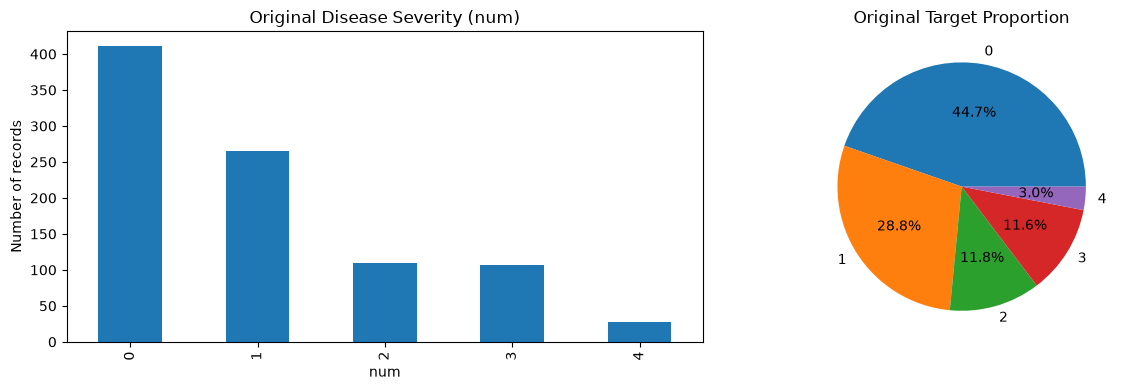

In [5]:
# 5. Target distribution (original target: num = 0, 1, 2, 3, 4)
if "num" not in df.columns:
    raise ValueError("Expected target column 'num' was not found.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["num"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Original Disease Severity (num)")
axes[0].set_xlabel("num")
axes[0].set_ylabel("Number of records")

df["num"].value_counts(normalize=True, dropna=False).sort_index().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Original Target Proportion")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [6]:
# 6. Convert target to binary
# num = 0 -> no disease; num > 0 -> disease
df = df.dropna(subset=["num"]).copy()
df["target"] = (df["num"] > 0).astype(int)

print(df["target"].value_counts().rename(index={0: "No disease", 1: "Disease"}))
print("\nTarget percentage:")
display((df["target"].value_counts(normalize=True) * 100).rename(index={0: "No disease", 1: "Disease"}).round(2))

target
Disease       509
No disease    411
Name: count, dtype: int64

Target percentage:


target
Disease       55.33
No disease    44.67
Name: proportion, dtype: float64

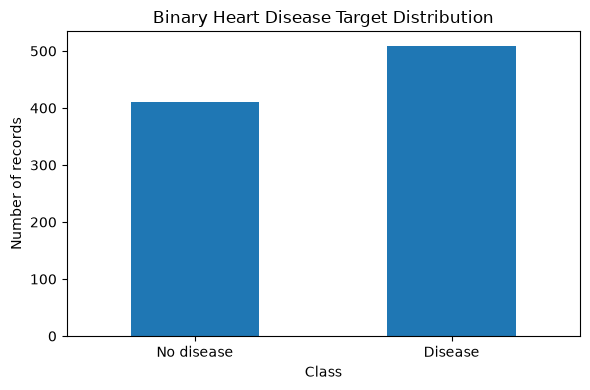

In [7]:
# 7. Binary target distribution
ax = df["target"].value_counts().sort_index().rename(index={0: "No disease", 1: "Disease"}).plot(
    kind="bar", figsize=(6, 4), rot=0
)
ax.set_title("Binary Heart Disease Target Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

In [8]:
# 8. Numerical and categorical feature identification
# id, dataset, num, and target are excluded from model inputs.
drop_from_features = [c for c in ["id", "dataset", "num", "target"] if c in df.columns]
X = df.drop(columns=drop_from_features)
y = df["target"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature matrix shape:", X.shape)

Numeric features: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Feature matrix shape: (920, 13)


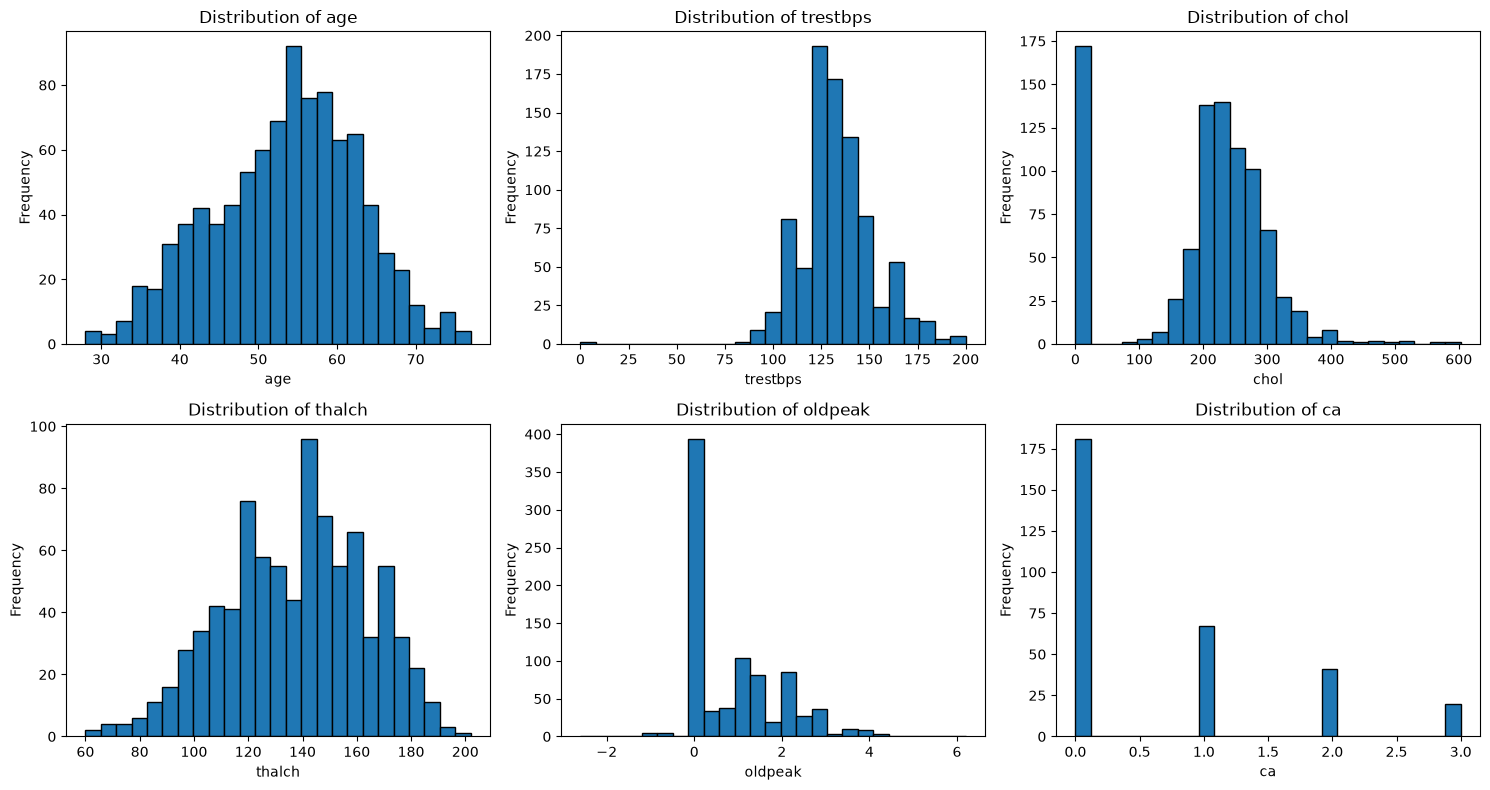

In [9]:
# 9. Numerical feature distributions
if numeric_features:
    ncols = 3
    nrows = int(np.ceil(len(numeric_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for i, col in enumerate(numeric_features):
        axes[i].hist(X[col].dropna(), bins=25, edgecolor="black")
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

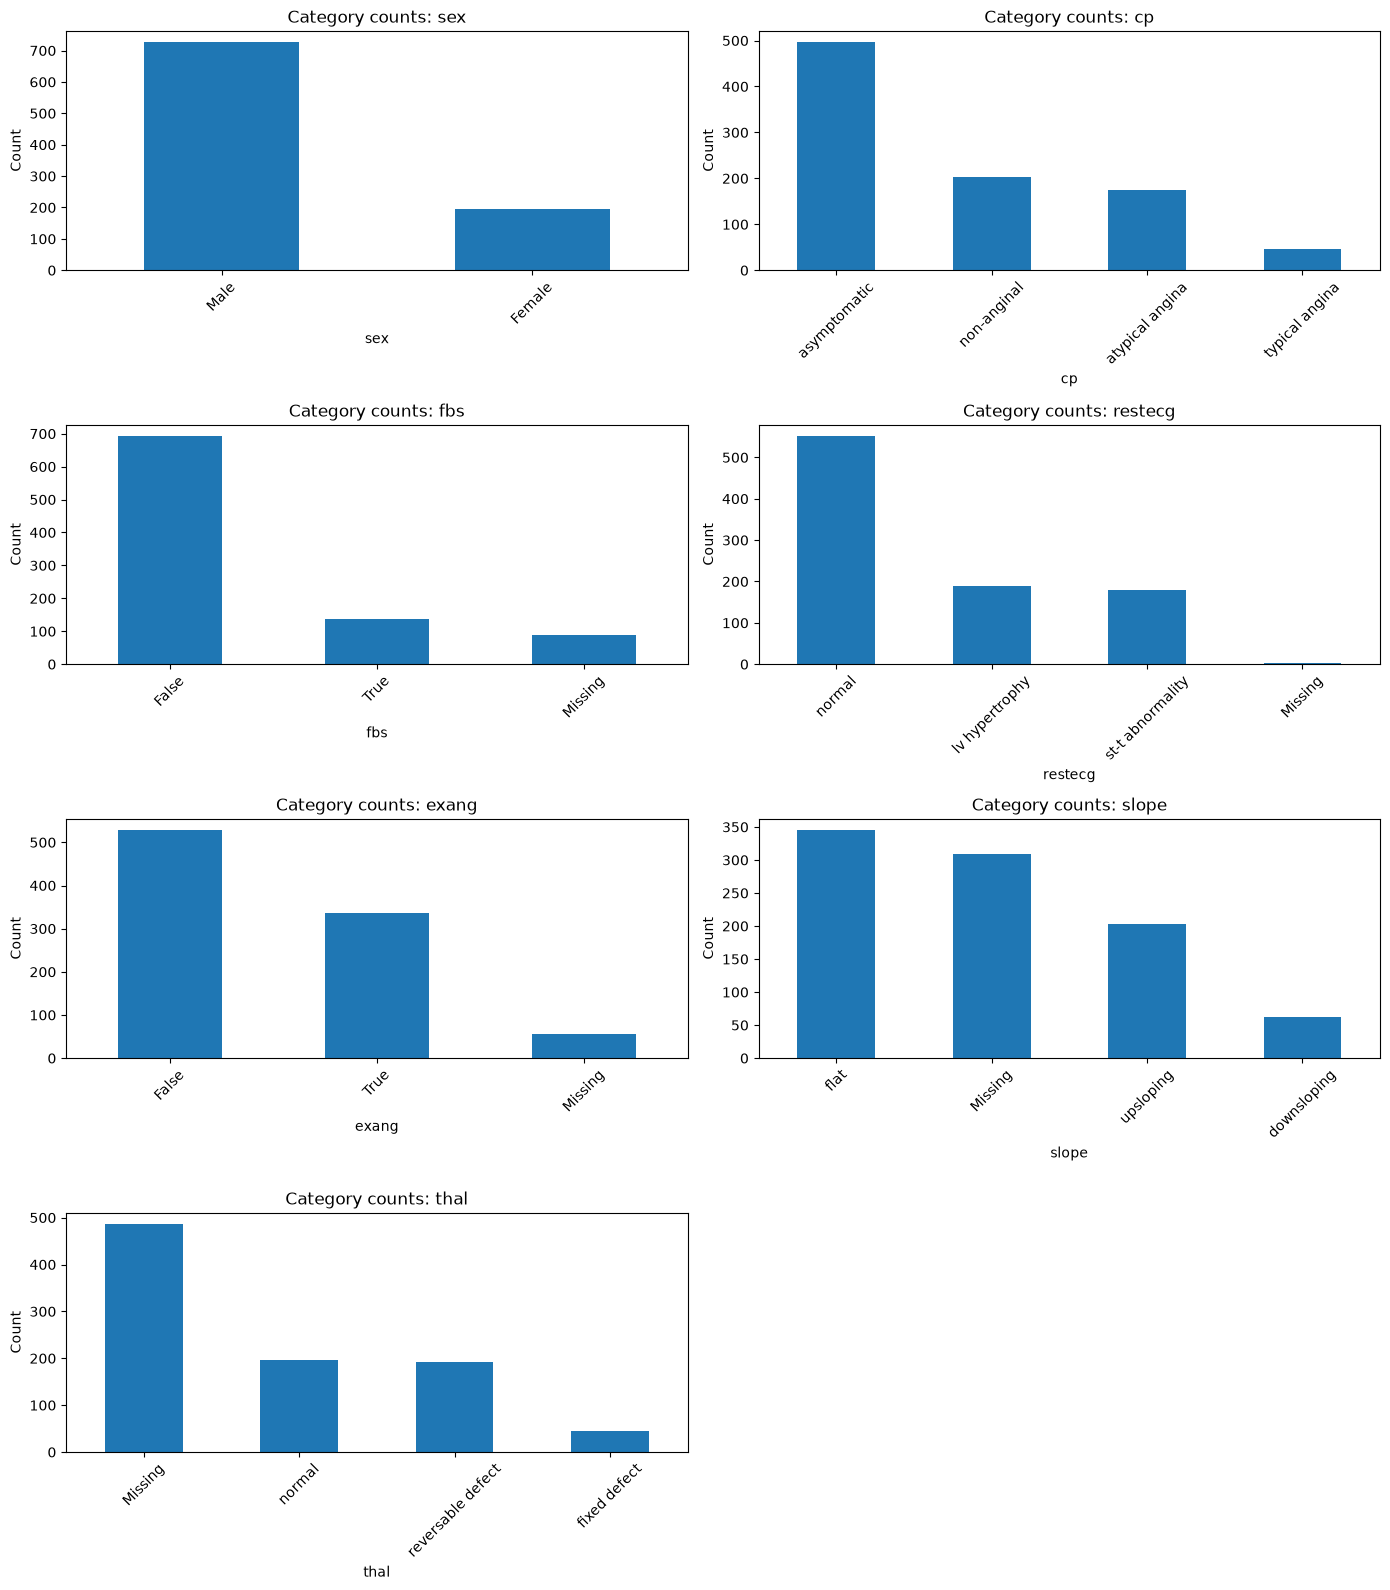

In [10]:
# 10. Categorical feature distributions
if categorical_features:
    ncols = 2
    nrows = int(np.ceil(len(categorical_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for i, col in enumerate(categorical_features):
        counts = X[col].astype("object").fillna("Missing").value_counts().head(15)
        counts.plot(kind="bar", ax=axes[i])
        axes[i].set_title(f"Category counts: {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
        axes[i].tick_params(axis="x", rotation=45)
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

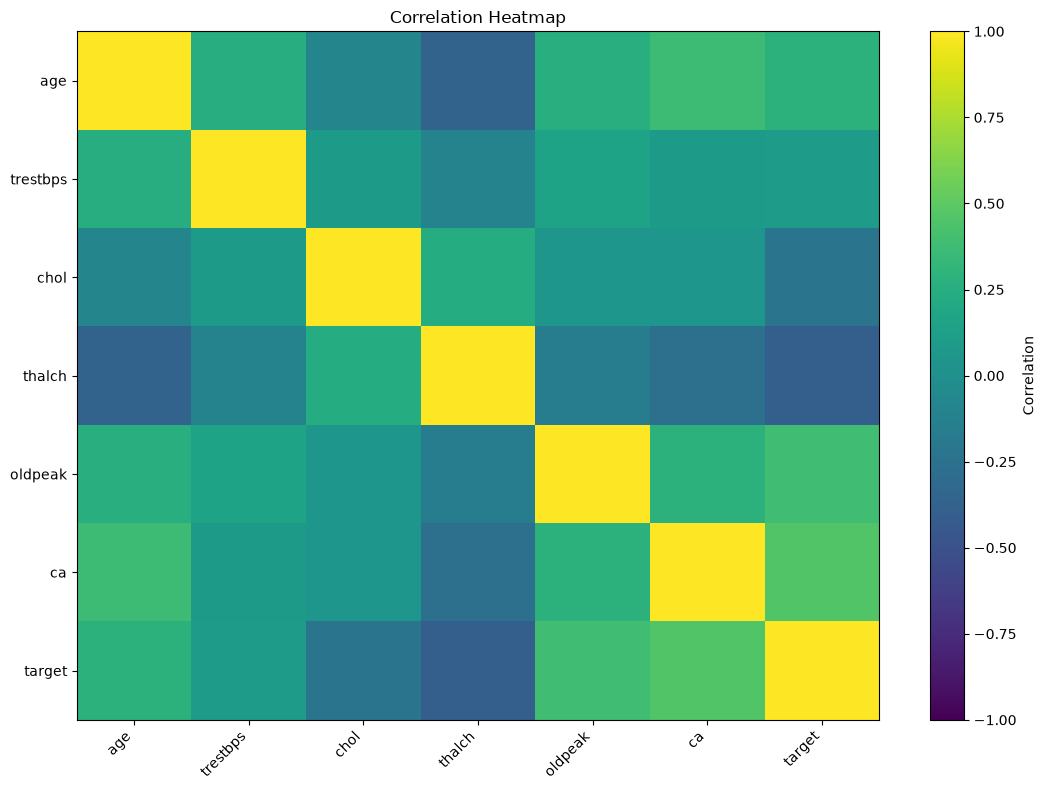

In [11]:
# 11. Numerical correlation heatmap (matplotlib only)
corr_cols = numeric_features + (["target"] if "target" not in numeric_features else [])
corr = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Heatmap")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

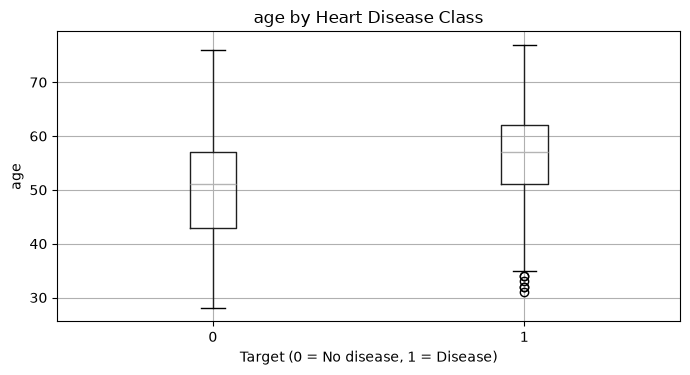

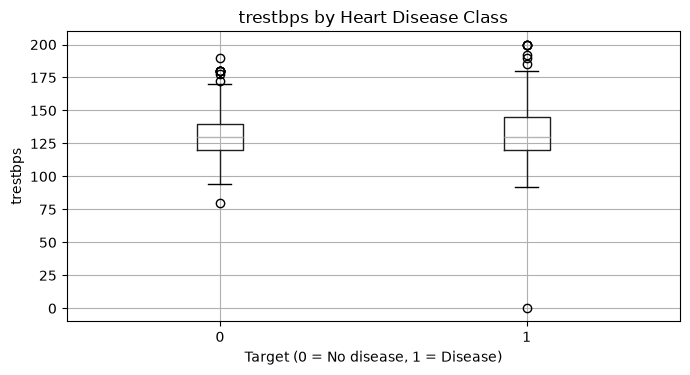

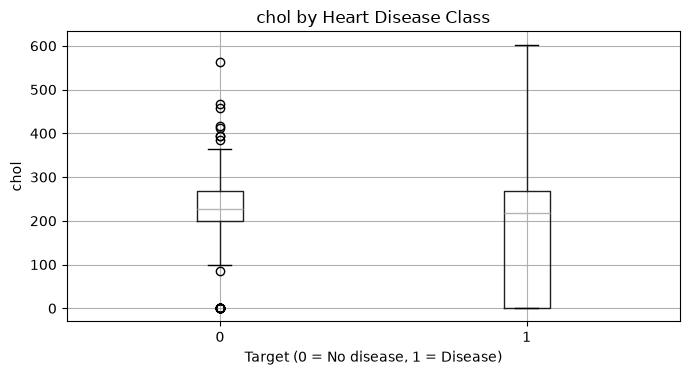

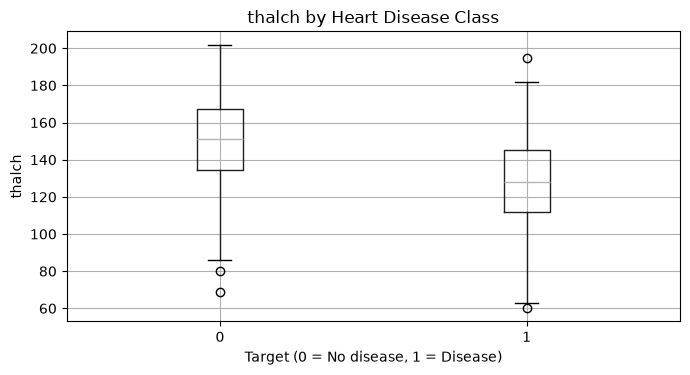

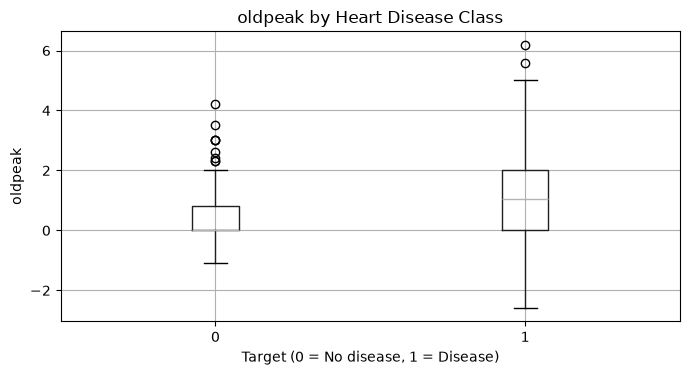

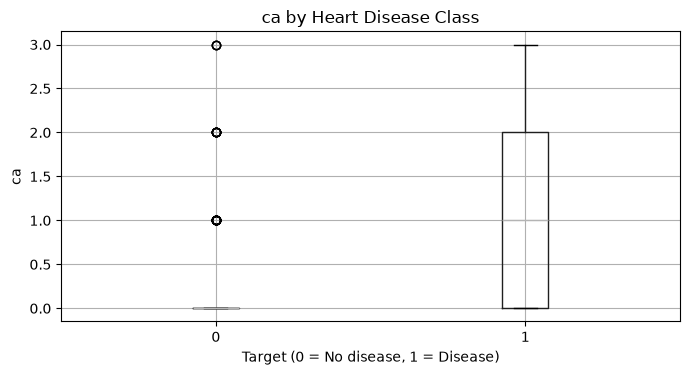

In [12]:
# 12. Numerical feature comparison by target class
for col in numeric_features:
    fig, ax = plt.subplots(figsize=(7, 4))
    df.boxplot(column=col, by="target", ax=ax)
    ax.set_title(f"{col} by Heart Disease Class")
    ax.set_xlabel("Target (0 = No disease, 1 = Disease)")
    ax.set_ylabel(col)
    fig.suptitle("")
    plt.tight_layout()
    plt.show()

## Data preprocessing

Preprocessing is fitted only on the training data through a scikit-learn `Pipeline` and `ColumnTransformer`. This prevents information from the test set leaking into imputation, scaling, or encoding. Missing numeric values use the median; categorical values use the most frequent category; categorical features are one-hot encoded.

In [13]:
# 13. Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3))
print("Testing target distribution:")
display(y_test.value_counts(normalize=True).round(3))

Training set: (736, 13)
Testing set: (184, 13)

Training target distribution:


target
1    0.553
0    0.447
Name: proportion, dtype: float64

Testing target distribution:


target
1    0.554
0    0.446
Name: proportion, dtype: float64

In [14]:
# 14. Build leakage-safe preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

## Baseline model training and cross-validation

The models below are evaluated on the same stratified hold-out test set. Five-fold stratified cross-validation is run on the training set only. Metrics include accuracy, precision, recall, F1-score, and ROC-AUC.

In [15]:
# 15. Define baseline models
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

baseline_rows = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    cv_result = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    baseline_rows.append({
        "Model": name,
        "CV Accuracy": cv_result["test_accuracy"].mean(),
        "CV Precision": cv_result["test_precision"].mean(),
        "CV Recall": cv_result["test_recall"].mean(),
        "CV F1": cv_result["test_f1"].mean(),
        "CV ROC-AUC": cv_result["test_roc_auc"].mean(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred, zero_division=0),
        "Test Recall": recall_score(y_test, pred, zero_division=0),
        "Test F1": f1_score(y_test, pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, proba)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("Test ROC-AUC", ascending=False)
display(baseline_results.round(4))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
1,Random Forest,0.8058,0.8266,0.8303,0.8263,0.8773,0.8533,0.8641,0.8725,0.8683,0.9219
2,Extra Trees,0.7922,0.8062,0.8304,0.8159,0.8646,0.8424,0.8349,0.8922,0.8626,0.9174
3,Gradient Boosting,0.7962,0.8094,0.8303,0.8185,0.8672,0.8533,0.8440,0.9020,0.8720,0.9075
0,Logistic Regression,0.8003,0.8337,0.8057,0.8170,0.8850,0.8315,0.8381,0.8627,0.8502,0.9041


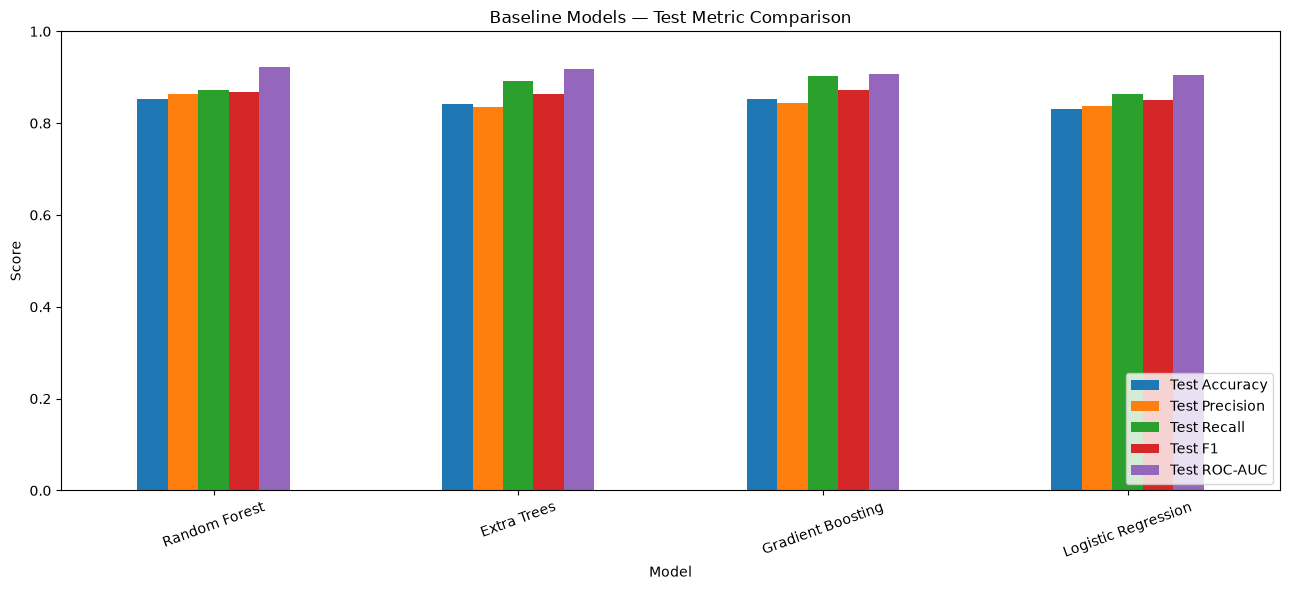

In [16]:
# 16. Baseline model comparison graphs
metrics_to_plot = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]
plot_df = baseline_results.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(kind="bar", figsize=(13, 6), ylim=(0, 1), rot=20)
ax.set_title("Baseline Models — Test Metric Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

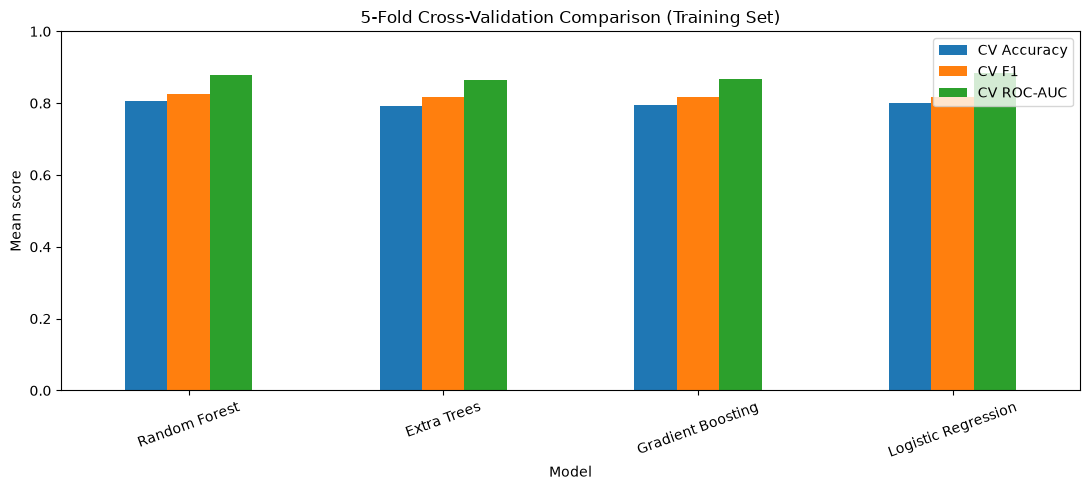

In [17]:
# 17. Cross-validation score comparison
cv_plot = baseline_results.set_index("Model")[["CV Accuracy", "CV F1", "CV ROC-AUC"]]
ax = cv_plot.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=20)
ax.set_title("5-Fold Cross-Validation Comparison (Training Set)")
ax.set_ylabel("Mean score")
ax.set_xlabel("Model")
plt.tight_layout()
plt.show()

## Hyperparameter tuning

Randomized search is used to tune Random Forest and Gradient Boosting. The search optimizes ROC-AUC using stratified 3-fold cross-validation on the training set. The test set remains untouched until final evaluation.

In [18]:
# 18. Tune Random Forest
rf_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

rf_params = {
    "model__n_estimators": [200, 250, 300, 400, 500],
    "model__max_depth": [None, 6, 8, 9, 12, 16],
    "model__min_samples_split": [2, 5, 8, 12],
    "model__min_samples_leaf": [1, 2, 3, 4],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_params, n_iter=12, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
rf_search.fit(X_train, y_train)

print("Best RF CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Best RF parameters:")
print(rf_search.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best RF CV ROC-AUC: 0.8899
Best RF parameters:
{'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 8, 'model__class_weight': 'balanced_subsample'}


In [19]:
# 19. Tune Gradient Boosting
gb_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

gb_params = {
    "model__n_estimators": [100, 150, 200, 250, 300],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [1, 2, 3],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.7, 0.85, 1.0]
}

gb_search = RandomizedSearchCV(
    gb_pipe, gb_params, n_iter=12, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
gb_search.fit(X_train, y_train)

print("Best GB CV ROC-AUC:", round(gb_search.best_score_, 4))
print("Best GB parameters:")
print(gb_search.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best GB CV ROC-AUC: 0.886
Best GB parameters:
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 1, 'model__learning_rate': 0.08}


In [20]:
# 20. Compare tuned models on the test set
tuned_models = {
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned Gradient Boosting": gb_search.best_estimator_
}

tuned_rows = []
for name, model in tuned_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    tuned_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred, zero_division=0),
        "Test Recall": recall_score(y_test, pred, zero_division=0),
        "Test F1": f1_score(y_test, pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, proba)
    })

tuned_results = pd.DataFrame(tuned_rows)
all_results = pd.concat([
    baseline_results[["Model", "Test Accuracy", "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"]],
    tuned_results
], ignore_index=True).sort_values("Test ROC-AUC", ascending=False)

display(all_results.round(4))

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
4,Tuned Random Forest,0.8750,0.8692,0.9118,0.8900,0.9259
0,Random Forest,0.8533,0.8641,0.8725,0.8683,0.9219
1,Extra Trees,0.8424,0.8349,0.8922,0.8626,0.9174
5,Tuned Gradient Boosting,0.8533,0.8505,0.8922,0.8708,0.9110
2,Gradient Boosting,0.8533,0.8440,0.9020,0.8720,0.9075
3,Logistic Regression,0.8315,0.8381,0.8627,0.8502,0.9041


In [21]:
# 21. Final model selection by test ROC-AUC (report this as exploratory, not final clinical selection)
best_name = all_results.iloc[0]["Model"]
model_lookup = {**fitted_models, **tuned_models}
best_model = model_lookup[best_name]

print("Top model on this hold-out split:", best_name)
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No disease", "Disease"], zero_division=0))

final_metrics = {
    "Accuracy": accuracy_score(y_test, best_pred),
    "Precision": precision_score(y_test, best_pred, zero_division=0),
    "Recall": recall_score(y_test, best_pred, zero_division=0),
    "F1-score": f1_score(y_test, best_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, best_proba)
}
display(pd.Series(final_metrics, name="Final test score").to_frame().round(4))

Top model on this hold-out split: Tuned Random Forest

Classification report:
              precision    recall  f1-score   support

  No disease       0.88      0.83      0.86        82
     Disease       0.87      0.91      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.87      0.87       184
weighted avg       0.88      0.88      0.87       184



,Final test score
Accuracy,0.8750
Precision,0.8692
Recall,0.9118
F1-score,0.8900
ROC-AUC,0.9259


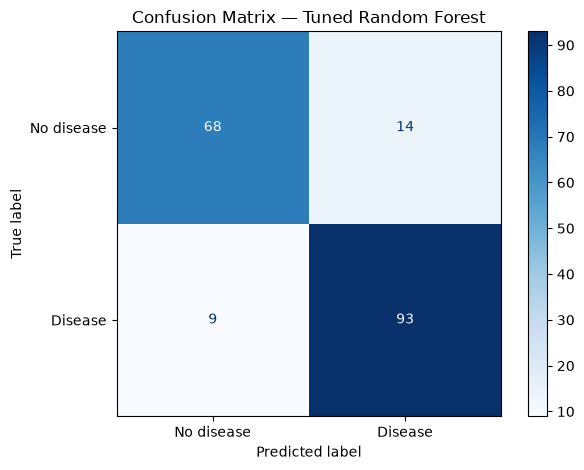

In [22]:
# 22. Final model confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["No disease", "Disease"],
    cmap="Blues", values_format="d"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

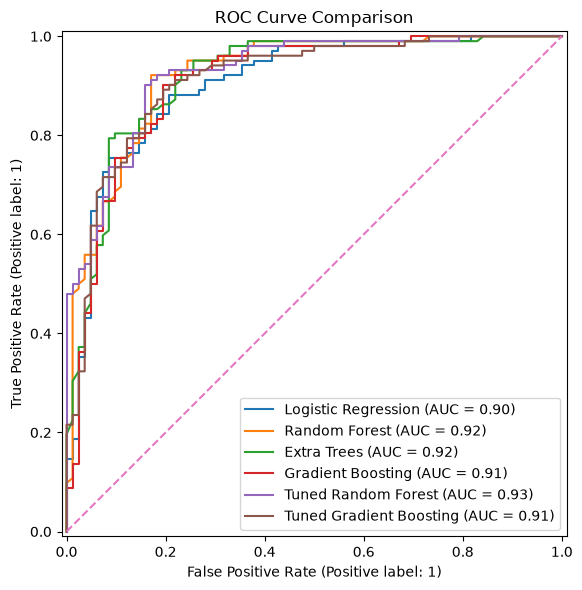

In [23]:
# 23. ROC curves for all baseline and tuned models
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in {**fitted_models, **tuned_models}.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

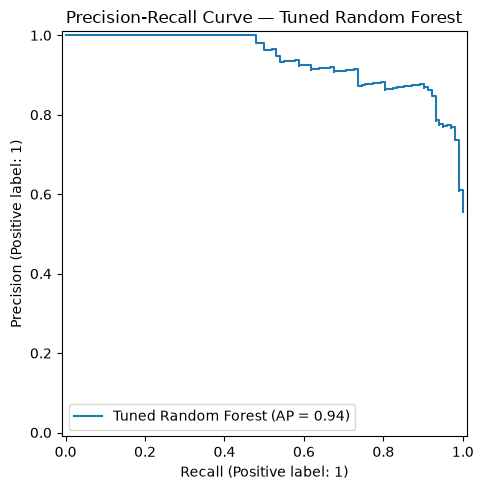

In [24]:
# 24. Precision-recall curve for the selected model
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=ax, name=best_name)
ax.set_title(f"Precision-Recall Curve — {best_name}")
plt.tight_layout()
plt.show()

,Feature,Importance Mean,Importance Std
2,cp,0.063725,0.014871
4,chol,0.035091,0.008463
8,exang,0.027523,0.006861
9,oldpeak,0.019058,0.006241
1,sex,0.012912,0.006550
7,thalch,0.008752,0.005842
12,thal,0.006755,0.006469
5,fbs,0.003682,0.002139
6,restecg,0.000837,0.002816
0,age,0.000789,0.002818


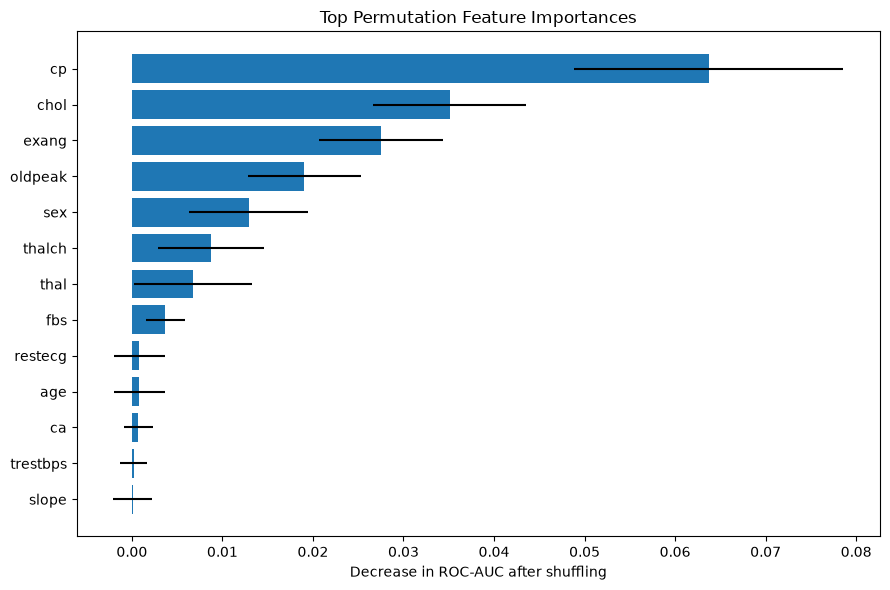

In [25]:
# 25. Permutation feature importance (works with the complete pipeline)
# This measures how much test score drops when one original input feature is shuffled.
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False)

display(importance_df)
top_imp = importance_df.head(15).sort_values("Importance Mean")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_imp["Feature"], top_imp["Importance Mean"], xerr=top_imp["Importance Std"])
ax.set_title("Top Permutation Feature Importances")
ax.set_xlabel("Decrease in ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

In [26]:
# 26. Save final model and results
joblib.dump(best_model, "best_heart_disease_uci_model.joblib")
baseline_results.to_csv("baseline_model_comparison.csv", index=False)
all_results.to_csv("all_model_comparison.csv", index=False)
importance_df.to_csv("permutation_feature_importance.csv", index=False)

print("Saved:")
print("- best_heart_disease_uci_model.joblib")
print("- baseline_model_comparison.csv")
print("- all_model_comparison.csv")
print("- permutation_feature_importance.csv")

Saved:
- best_heart_disease_uci_model.joblib
- baseline_model_comparison.csv
- all_model_comparison.csv
- permutation_feature_importance.csv


## Interpretation and limitations

- The binary target merges severity labels `1–4` into one disease class; severity-specific prediction is not performed.
- The dataset contains records from multiple source populations and is relatively small. A single random train/test split can produce unstable estimates.
- Missing values are substantial in some columns (notably `ca`, `thal`, and `slope`); imputation can affect model behavior.
- The best model in this notebook is selected from a hold-out split for educational comparison. For a stronger research result, use nested/repeated cross-validation, calibration analysis, subgroup evaluation, and external validation on an independent cohort.
- Do not interpret model output as a medical diagnosis. The UCI dataset's `restecg` feature is an ECG interpretation category, not a raw ECG waveform; it cannot train a CNN–BiLSTM waveform branch.
- No SMOTE is applied by default. If imbalance handling is tested, it must be applied only within training folds (for example, using an imbalanced-learn pipeline), never before the train/test split.

## Previously obtained reference run

In one completed run on this dataset using an 80/20 stratified split (`random_state=42`), the tuned Random Forest achieved approximately:

| Metric | Score |
|---|---:|
| Accuracy | 87.50% |
| Precision | 85.59% |
| Recall | 93.14% |
| F1-score | 89.20% |
| ROC-AUC | 92.69% |

Your results may differ depending on package versions, preprocessing details, and the search space. Always use the output produced by running this notebook as the authoritative result for your environment.